# Gas Chromatography Analysis

Read a LabSolutions text export, validate the signal and compound tables, and produce five complementary views of a gas chromatography measurement.

The example is the supplied **231221_C37** sample. It contains one measured chromatogram; no reference oils or synthetic comparison samples are added.

## Run this notebook

Open the notebook from the project root, with `data/Gaschroma.txt` present, and run every cell in order. The [README](README.md) describes installation and command-line execution. All analysis functions remain visible below for step-by-step learning.

| Figure | Question it answers |
| --- | --- |
| Full chromatogram | What happened across the complete run? |
| Zoomed chromatogram | Which smaller peaks are visible between 4 and 16 minutes? |
| Maximum-normalized trace | What is the signal shape on a relative scale? |
| Compound bars | Which reported compound percentages are largest? |
| Compound heatmap | What does the complete positive compound profile look like? |

The raw signal is read from `[Chromatogram (Ch1)]`; compound values come from `[Compound Results(Ch1)]`. The export specifies retention time in minutes but does not specify a physical intensity unit.

## 1. Libraries and settings

The input filename and folder, display range, figure size, and saving option are defined at the beginning of the program. The default input directory is `data`, relative to the project root. For another input file, change the settings; the functions can be reused.

The 4-to-16-minute range is selected to display the peaks in more detail. The full chromatogram is also plotted separately.

The additional settings define a dictionary of real sample labels and file paths. With one file, the new plots are single-sample previews. Add reference and mixture files to `SAMPLE_FILES` to use the same functions for comparisons.

`COMPOUND_METRIC` selects the basis of the bar chart and heatmap:

- `reported_percent`: use the instrument-exported `Conc. %` values directly.
- `area_percent`: calculate each compound's area as a percentage of the total area in the **Compound Results** table.

The second option has a different denominator from all detected peaks: unassigned peaks outside the compound table are excluded. It is an uncorrected area fraction, not a validated concentration or an oil mixing fraction.


In [1]:
from pathlib import Path
import csv
import hashlib

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "semibold",
    "figure.dpi": 110,
    "savefig.bbox": "tight",
})

INPUT_DIRECTORY = Path("data")
INPUT_FILENAME = "Gaschroma.txt"
INPUT_PATH = INPUT_DIRECTORY / INPUT_FILENAME
ENCODING = "utf-8-sig"
SECTION = "[Chromatogram (Ch1)]"

START_TIME = 4.0
END_TIME = 16.0
FIGURE_SIZE = (11, 4)

SAVE_PLOTS = True
OUTPUT_DIRECTORY = Path("results")
FULL_PLOT_FILENAME = "Gaschroma_full.png"
ZOOM_PLOT_FILENAME = "Gaschroma_zoom.png"
DPI = 200

# Additional visualization settings
SAMPLE_FILES = {
    "231221_C37": INPUT_PATH,
    # Add actual files here when available, for example:
    # "Reference oil A": INPUT_DIRECTORY / "reference_A.txt",
    # "Reference oil B": INPUT_DIRECTORY / "reference_B.txt",
    # "Unknown mixture": INPUT_DIRECTORY / "unknown_mixture.txt",
}
COMPOUND_SECTION = "[Compound Results(Ch1)]"
NORMALIZATION_START = START_TIME
NORMALIZATION_END = END_TIME
COMPOUND_METRIC = "reported_percent"  # Alternative: "area_percent"
TOP_COMPOUNDS = 12
ANNOTATE_HEATMAP = True
OVERLAY_PLOT_FILENAME = "Gaschroma_normalized_overlay.png"
BAR_PLOT_FILENAME = "Gaschroma_compound_bars.png"
HEATMAP_PLOT_FILENAME = "Gaschroma_compound_heatmap.png"

## 2. Read and validate the export

Read the supplied UTF-8 text file, then locate sections by their names. The helpers check metadata counts, array shapes, finite values, and strictly increasing retention times. Invalid data raise an explanatory error instead of being silently removed, sorted, or interpolated.

Negative detector intensities are valid in this export and are preserved. Neither baseline correction nor smoothing is applied.

In [2]:
def read_file(file_path, encoding="utf-8-sig"):
    """Read a local export, allowing a UTF-8 byte-order mark."""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(
            f"Data file not found: {path}. Run from the project root "
            "or update INPUT_DIRECTORY and INPUT_FILENAME."
        )
    return path.read_text(encoding=encoding).splitlines()


def extract_section(lines, section):
    """Find one named section without assuming fixed line numbers."""
    matches = [i for i, line in enumerate(lines) if line.strip() == section]
    if len(matches) != 1:
        raise ValueError(f"Expected exactly one section {section}; found {len(matches)}.")
    block = []
    for line in lines[matches[0] + 1:]:
        stripped = line.strip()
        if stripped.startswith("[") and stripped.endswith("]"):
            break
        if stripped:
            block.append(line)
    return block


def reported_count(lines, key):
    """Require a single, positive integer count in the section metadata."""
    values = []
    for line in lines:
        fields = line.split("\t")
        if fields[0].strip() == key:
            if len(fields) != 2:
                raise ValueError(f"Malformed count metadata: {key}.")
            values.append(fields[1].strip())
    if len(values) != 1:
        raise ValueError(f"Expected exactly one {key} metadata entry.")
    try:
        count = int(values[0])
    except ValueError as error:
        raise ValueError(f"{key} must be an integer.") from error
    if count <= 0:
        raise ValueError(f"{key} must be positive.")
    return count


def validate_signal(retention_time, intensity):
    """Reject incomplete, non-finite, or out-of-order signal arrays."""
    time = np.asarray(retention_time, dtype=float)
    signal = np.asarray(intensity, dtype=float)
    if time.ndim != 1 or signal.shape != time.shape or time.size < 2:
        raise ValueError("Retention time and intensity must be matching 1D arrays with at least two points.")
    if not np.isfinite(time).all() or not np.isfinite(signal).all():
        raise ValueError("Retention time and intensity must contain only finite values.")
    if np.any(np.diff(time) <= 0):
        raise ValueError("Retention times must be strictly increasing; duplicate times are not accepted.")
    # Negative detector values are allowed; the recorded baseline is preserved.
    return time, signal


def select_window(retention_time, intensity, start_time=None, end_time=None):
    """Select a finite time window without modifying the source arrays."""
    time, signal = validate_signal(retention_time, intensity)
    for bound in (start_time, end_time):
        if bound is not None and not np.isfinite(bound):
            raise ValueError("Time-window limits must be finite.")
    if start_time is not None and end_time is not None and start_time >= end_time:
        raise ValueError("The start time must be less than the end time.")
    mask = np.ones(time.size, dtype=bool)
    if start_time is not None:
        mask &= time >= start_time
    if end_time is not None:
        mask &= time <= end_time
    if np.count_nonzero(mask) < 2:
        raise ValueError("The selected time window must contain at least two measurement points.")
    return time[mask], signal[mask]

## 3. Data-extraction function

The function first finds the signal section, then locates the column header. It therefore does not depend on fixed line numbers. Reading stops when the next section begins.

Time values in the file use decimal commas. Each comma is replaced with a decimal point so that the values can be converted to numbers.

The function returns two numeric arrays: retention time and intensity. Matching indices in the arrays refer to the same measurement point. The number of extracted points is checked against the count recorded in the file so that an incomplete file is not processed silently.


In [3]:
def extract_chromatogram(lines, section="[Chromatogram (Ch1)]"):
    """Parse the complete two-column chromatogram and validate its point count."""
    block = extract_section(lines, section)
    rows = [[field.strip() for field in row] for row in csv.reader(block, delimiter="\t")]
    headers = [i for i, row in enumerate(rows) if row == ["R.Time (min)", "Intensity"]]
    if len(headers) != 1:
        raise ValueError("Expected one 'R.Time (min)' / 'Intensity' column header.")
    header_index = headers[0]
    expected = reported_count(block[:header_index], "# of Points")
    numeric_rows = []
    for row_number, row in enumerate(rows[header_index + 1:], start=1):
        if len(row) != 2:
            raise ValueError(f"Signal row {row_number} must contain exactly two columns.")
        try:
            numeric_rows.append([float(value.replace(",", ".")) for value in row])
        except ValueError as error:
            raise ValueError(f"Signal row {row_number} contains a non-numeric value.") from error
    if len(numeric_rows) != expected:
        raise ValueError(f"Expected {expected} signal points; read {len(numeric_rows)}.")
    data = np.asarray(numeric_rows, dtype=float)
    return validate_signal(data[:, 0], data[:, 1])

## 4. Plotting function

The horizontal axis shows retention time in minutes; the vertical axis shows signal intensity. Without time limits, all points are plotted. With a start and end time, only points within that range are selected for plotting. The original arrays remain complete.

For the zoomed view, the vertical scale is calculated from the selected points. This prevents smaller peaks from being compressed by the very large peak near the beginning of the full chromatogram.

The function returns the figure so that the main program can save it.


In [4]:
def plot_chromatogram(
    retention_time, intensity, start_time=None, end_time=None,
    figure_size=(11, 4), title="Chromatogram",
):
    """Plot the full signal or a selected window using the original intensities."""
    time, signal = select_window(retention_time, intensity, start_time, end_time)
    fig, ax = plt.subplots(figsize=figure_size, layout="constrained")
    ax.plot(time, signal, color="#176B87", linewidth=0.8)
    ax.set_xlabel("Retention time [min]")
    ax.set_ylabel("Detector intensity [export units]")
    ax.set_title(title)
    ax.set_axisbelow(True)
    ax.grid(alpha=0.2)
    ax.margins(x=0)
    return fig

## 5. Running the program

The main program calls the three functions in order: read the file, extract the data, and plot the chromatogram. It prints the number of points and the actual time range, then creates a full plot and a plot of the selected time range.

If saving is enabled, both images are saved in this folder:

```text
results
```

Change the display range or input filename in the settings cell. After changing the settings, run the cells again from the top.


File: data/Gaschroma.txt
Measurement points: 25,500
Time range: 0.00017 to 16.99950 min


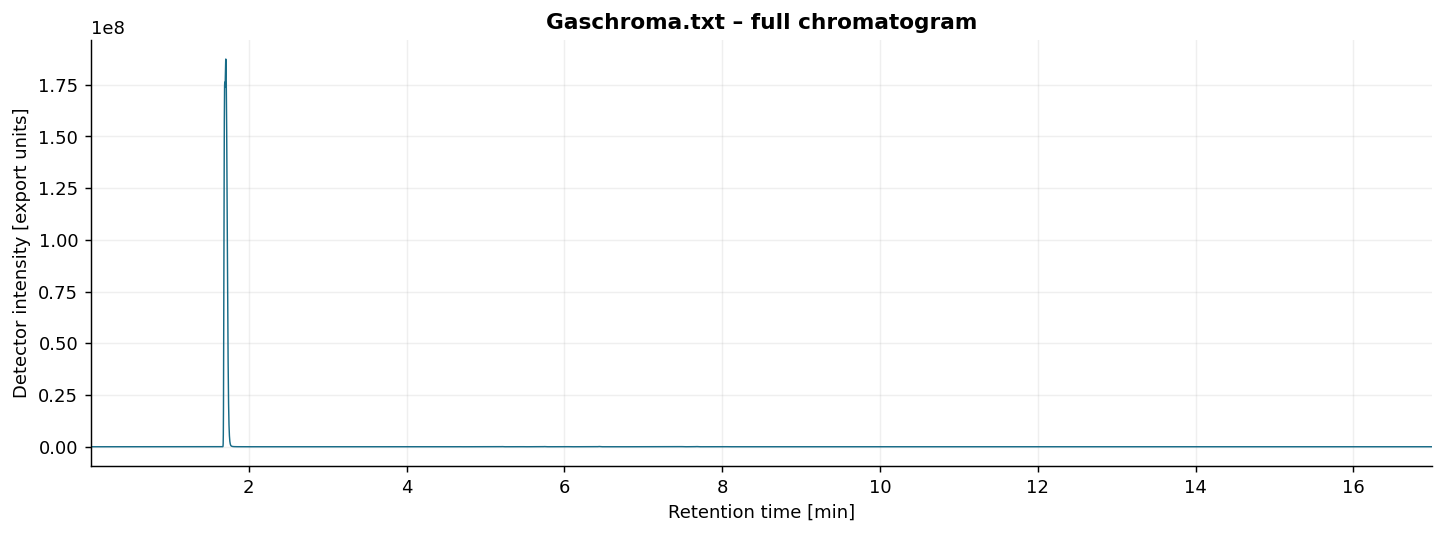

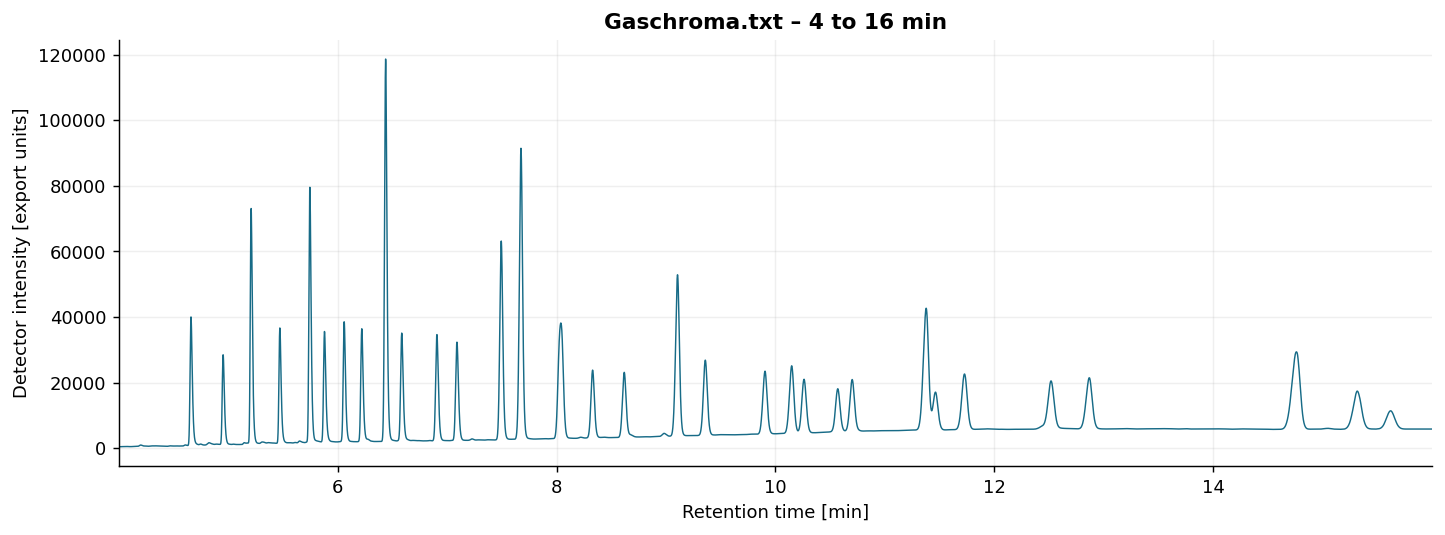

In [5]:
def main():
    lines = read_file(INPUT_PATH, ENCODING)
    retention_time, intensity = extract_chromatogram(lines, SECTION)

    print(f"File: {INPUT_PATH}")
    print(f"Measurement points: {len(retention_time):,}")
    print(f"Time range: {retention_time.min():.5f} to {retention_time.max():.5f} min")

    full_figure = plot_chromatogram(
        retention_time, intensity,
        figure_size=FIGURE_SIZE,
        title=f"{INPUT_FILENAME} – full chromatogram",
    )
    zoom_figure = plot_chromatogram(
        retention_time, intensity,
        start_time=START_TIME, end_time=END_TIME,
        figure_size=FIGURE_SIZE,
        title=f"{INPUT_FILENAME} – {START_TIME:g} to {END_TIME:g} min",
    )

    if SAVE_PLOTS:
        OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
        full_figure.savefig(OUTPUT_DIRECTORY / FULL_PLOT_FILENAME, dpi=DPI)
        zoom_figure.savefig(OUTPUT_DIRECTORY / ZOOM_PLOT_FILENAME, dpi=DPI)

    plt.show()


main()


## Results for the supplied file

| Measurement | Result |
|---|---:|
| Number of signal points | 25,500 |
| First recorded time, minutes | 0.00017 |
| Last recorded time, minutes | 16.99950 |
| Points in the 4-to-16-minute view | 18,000 |

Actual times are read from the data column. The 17-minute value is the nominal end time recorded in the file header.


# Additional scientific visualizations

The supplied file contains one sample, 35 compound rows, and 31 positive `Conc. %` values. The exported percentages sum to 100.000% in this file. The example sample label comes from the export's sample information; no oil identity is assigned.

These views answer different questions:

| View | What it shows | Current dataset |
|---|---|---|
| Normalized overlay | Peak positions and signal shapes on a common relative scale | One normalized trace; overlays appear when more files are loaded |
| Compound bar chart | Reported compound values, with the largest values displayed | Top 12 of 31 positive compound labels |
| Compound heatmap | A shared scale across the full selected compound profile | One-row preview; one row per real sample when more files are loaded |

The raw full and zoomed chromatograms above remain the starting point for interpreting the signal.


## 6. Read compound results and load real samples

The signal section and the compound table contain different information. The first has 25,500 measurement points; the second contains the instrument's named compound results.

The parser reads the compound table by its section and column headers. It preserves labels exactly, including `C18:1 cis/trans`, `C18:2 cis/trans`, `C18:3n3`, and `C18:3n6`. A combined cis/trans report entry is not split into invented components.

Each configured sample is loaded from its own file. Duplicate file paths and byte-identical copies under different names are rejected. A renamed copy is not an independent measurement.


In [6]:
def extract_compound_results(lines, section="[Compound Results(Ch1)]"):
    """Read the named compound table; preserve labels and explicit zeros."""
    block = extract_section(lines, section)
    rows = [[field.strip() for field in row] for row in csv.reader(block, delimiter="\t")]
    headers = [i for i, row in enumerate(rows) if row and row[0] == "ID#"]
    if len(headers) != 1:
        raise ValueError("Expected exactly one compound table header beginning with 'ID#'.")
    header_index = headers[0]
    header = rows[header_index]
    required = {"ID#", "Name", "R.Time", "Area", "Conc. %"}
    if not required.issubset(header) or len(header) != len(set(header)):
        raise ValueError("The compound table has missing or duplicate column names.")
    expected = reported_count(block[:header_index], "# of IDs")
    compounds = []
    ids = []
    for row_number, fields in enumerate(rows[header_index + 1:], start=1):
        if len(fields) != len(header):
            raise ValueError(f"Compound row {row_number} has {len(fields)} columns; expected {len(header)}.")
        row = dict(zip(header, fields))
        try:
            compound_id = int(row["ID#"])
            values = [float(row[name].replace(",", ".")) for name in ("R.Time", "Area", "Conc. %")]
        except ValueError as error:
            raise ValueError(f"Compound row {row_number} contains a non-numeric value.") from error
        if compound_id <= 0 or not np.isfinite(values).all() or any(value < 0 for value in values):
            raise ValueError(f"Compound row {row_number} requires a positive ID and finite, nonnegative values.")
        ids.append(compound_id)
        compounds.append({
            "name": row["Name"],
            "retention_time": values[0],
            "area": values[1],
            "reported_percent": values[2],
        })
    if len(compounds) != expected:
        raise ValueError(f"Expected {expected} compound rows; read {len(compounds)}.")
    names = [row["name"] for row in compounds]
    if any(not name for name in names) or len(set(names)) != len(names) or len(set(ids)) != len(ids):
        raise ValueError("Compound IDs and labels must be present and unique within each file.")
    return compounds


def load_samples(sample_files, encoding, signal_section, compound_section):
    """Load genuine exports; reject duplicate paths or byte-identical copies."""
    if not sample_files:
        raise ValueError("Configure at least one sample file.")
    if any(not isinstance(label, str) or not label.strip() for label in sample_files):
        raise ValueError("Sample labels must be nonempty strings.")
    paths = [Path(path).resolve() for path in sample_files.values()]
    if len(paths) != len(set(paths)):
        raise ValueError("Different sample labels must refer to different files.")
    samples = {}
    fingerprints = set()
    for label, path in zip(sample_files, paths):
        lines = read_file(path, encoding)
        fingerprint = hashlib.sha256(path.read_bytes()).hexdigest()
        if fingerprint in fingerprints:
            raise ValueError("Byte-identical export files cannot be used as independent samples.")
        fingerprints.add(fingerprint)
        retention_time, intensity = extract_chromatogram(lines, signal_section)
        samples[label] = {
            "retention_time": retention_time,
            "intensity": intensity,
            "compounds": extract_compound_results(lines, compound_section),
        }
    return samples

## 7. Normalize and overlay chromatograms

For each sample, select the same time window and divide the intensity by the maximum **inside that window**:

$$I_{\mathrm{norm},s}(t)=\frac{I_s(t)}{\max_{u\in W} I_s(u)},\qquad W=[4,16]\ \mathrm{min}.$$

Using the full-run maximum would make the very large early peak dominate the scale in this file. Window-based scaling keeps the later peaks visible. The original intensities are retained, and no baseline subtraction or smoothing is applied.

The result is a visual comparison of signal shapes. A normalized height of 0.5 means half the largest intensity in that sample's selected window; it does **not** mean 50% concentration or 50% oil content.

The function keeps each sample's original retention times. It does not automatically shift or align peaks. Compare runs measured under compatible chromatographic conditions and investigate shifts before interpreting peak matches.

Every sample must cover the entire selected time window; partial windows are rejected so that their different maxima are not presented as directly comparable scales.


In [7]:
def normalize_signal(retention_time, intensity, start_time, end_time):
    """Scale by the maximum inside a fully covered comparison window."""
    time, signal = validate_signal(retention_time, intensity)
    selected_time, selected_signal = select_window(time, signal, start_time, end_time)
    if start_time < time[0] or end_time > time[-1]:
        raise ValueError("Every sample must cover the complete normalization window.")
    maximum = selected_signal.max()
    if maximum <= 0:
        raise ValueError("Normalization requires a positive signal maximum.")
    return selected_time, selected_signal / maximum


def plot_normalized_overlay(samples, start_time, end_time, figure_size):
    """Compare shapes on a shared window without changing retention times."""
    if not samples:
        raise ValueError("At least one sample is required for an overlay.")
    traces = [
        (label, *normalize_signal(sample["retention_time"], sample["intensity"], start_time, end_time))
        for label, sample in samples.items()
    ]
    fig, ax = plt.subplots(figsize=figure_size, layout="constrained")
    for label, time, normalized in traces:
        ax.plot(time, normalized, linewidth=0.9, alpha=0.9, label=label)
    ax.set_xlabel("Retention time [min]")
    ax.set_ylabel("Window-normalized intensity")
    title = "Normalized chromatogram overlay" if len(samples) > 1 else "Normalized chromatogram - one sample"
    ax.set_title(f"{title}\nMaximum scaling within {start_time:g}-{end_time:g} min")
    ax.set_xlim(start_time, end_time)
    ax.set_axisbelow(True)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    return fig

## 8. Build comparable compound profiles

Rows correspond to samples and columns correspond to exact compound labels. The default values come directly from `Conc. %` in the report. They are instrument-calculated results; their calibration quality is not established by this notebook.

The optional area mode calculates:

$$p_{i,s}^{\mathrm{area}}=100\,\frac{A_{i,s}}{\sum_{j\in\mathrm{Compound\ Results}} A_{j,s}}.$$

The denominator includes only the named compounds in that table. This calculation does not compensate for differences in detector response.

A missing compound row is stored as a missing value. An explicit zero from the report remains zero. A zero result does not by itself prove chemical absence. Columns that are zero in every loaded sample are omitted from the plots; the full extracted records are retained in `samples`.


In [8]:
def build_compound_matrix(samples, metric="reported_percent"):
    """Align compounds by exact report labels; keep missing entries as NaN."""
    if not samples:
        raise ValueError("At least one sample is required to build a compound matrix.")
    if metric not in {"reported_percent", "area_percent"}:
        raise ValueError("Choose 'reported_percent' or 'area_percent'.")
    sample_names = list(samples)
    profiles = []
    compound_names = []
    for sample in samples.values():
        compounds = sample["compounds"]
        names = [row["name"] for row in compounds]
        if not names or any(not name for name in names) or len(set(names)) != len(names):
            raise ValueError("Each sample needs nonempty, unique compound labels.")
        if metric == "reported_percent":
            values = np.array([row["reported_percent"] for row in compounds])
            value_label = "Instrument-reported Conc. %"
        elif metric == "area_percent":
            areas = np.array([row["area"] for row in compounds])
            if areas.sum() <= 0:
                raise ValueError("The reported compound areas must have a positive sum.")
            values = 100 * areas / areas.sum()
            value_label = "Area share of reported compounds [%]"
        else:
            raise ValueError("Choose 'reported_percent' or 'area_percent'.")
        if not np.isfinite(values).all() or (values < 0).any():
            raise ValueError("Compound values must be finite and nonnegative.")

        profile = dict(zip([row["name"] for row in compounds], values))
        profiles.append(profile)
        for name in profile:
            if name not in compound_names:
                compound_names.append(name)

    # Keep compounds with a positive value in at least one loaded sample.
    compound_names = [name for name in compound_names if any(profile.get(name, 0) > 0 for profile in profiles)]
    if not compound_names:
        raise ValueError("No positive compound values are available for plotting.")
    matrix = np.array([[profile.get(name, np.nan) for name in compound_names] for profile in profiles])
    return sample_names, compound_names, matrix, value_label

## 9. Compound composition bar chart

The chart displays the largest values across the loaded samples. For the default settings, it shows 12 compound labels. Each sample has its own bar color.

The displayed subset is **not renormalized** to 100%. Each bar keeps its original reported value and the report's original percentage basis. Missing entries are not plotted.

Use these bars to compare compound profiles. A bar labeled 7.39% for `C24:0` describes the reported compound percentage in this file; it does not describe the share of an oil in a mixture.


In [9]:
def plot_compound_bars(sample_names, compound_names, matrix, value_label, top_n=12):
    """Plot the largest reported values without renormalizing the displayed subset."""
    if isinstance(top_n, bool) or not isinstance(top_n, (int, np.integer)) or top_n <= 0:
        raise ValueError("TOP_COMPOUNDS must be a positive integer.")
    order = np.argsort(-np.nanmax(matrix, axis=0), kind="stable")[:top_n]
    names = [compound_names[index] for index in order]
    fig, ax = plt.subplots(figsize=(11, max(4, len(names) * 0.42 + 1.4)))
    y = np.arange(len(names))
    height = 0.8 / len(sample_names)
    colors = plt.get_cmap("tab10")
    for index, sample_name in enumerate(sample_names):
        offset = (index - (len(sample_names) - 1) / 2) * height
        ax.barh(y + offset, matrix[index, order], height=height,
                color=colors(index % 10), label=sample_name)
    if len(sample_names) == 1:
        ax.bar_label(ax.containers[0], fmt="%.3f", padding=4, fontsize=9)
        ax.margins(x=0.12)
    ax.set_yticks(y, names)
    ax.invert_yaxis()
    ax.set_xlabel(value_label)
    ax.set_ylabel("Compound label from the instrument report")
    ax.set_title(f"Compound composition - top {len(names)} of {len(compound_names)} positive labels")
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.legend(frameon=False, loc="lower right")
    fig.tight_layout()
    return fig

## 10. Compound fingerprint heatmap

The heatmap includes every compound with a positive value in at least one loaded sample. All rows share one color scale, so the same color means the same percentage value across samples. No separate scaling is applied to each row.

Grey cells marked `NA` represent missing table entries; numeric zero represents an explicit zero from the report. Values are printed inside the cells for small matrices.

With one supplied file, the figure is a single-sample preview. With multiple reference oils and mixtures, the rows show similarities and differences in their reported compound profiles. The visualization does not classify oils or estimate mixture fractions automatically.


In [10]:
def plot_compound_heatmap(sample_names, compound_names, matrix, value_label, annotate=True):
    """Use a shared percentage scale for all samples; distinguish missing from zero."""
    fig, ax = plt.subplots(figsize=(max(10, len(compound_names) * 0.52), max(3.4, len(sample_names) * 0.6 + 2.5)))
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("#dddddd")
    maximum = np.nanmax(matrix)
    image = ax.imshow(np.ma.masked_invalid(matrix), aspect="auto", cmap=cmap, vmin=0, vmax=maximum)
    ax.set_xticks(np.arange(len(compound_names)), compound_names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(np.arange(len(sample_names)), sample_names)
    title = "Compound fingerprints" if len(sample_names) > 1 else "Compound fingerprint - single-sample preview"
    ax.set_title(title)
    ax.set_xlabel("Compound label from the instrument report")
    colorbar = fig.colorbar(image, ax=ax, pad=0.015, fraction=0.035)
    colorbar.set_label(value_label)
    if annotate and matrix.size <= 200:
        for row in range(matrix.shape[0]):
            for column in range(matrix.shape[1]):
                value = matrix[row, column]
                text = "NA" if np.isnan(value) else f"{value:.2f}"
                color = "#444444" if np.isnan(value) else ("white" if value < maximum * 0.55 else "black")
                ax.text(column, row, text, ha="center", va="center", fontsize=7, color=color)
    fig.tight_layout()
    return fig

## 11. Run the additional visualizations

This cell loads the configured real files, prints the compound-table summary, and produces the three added figures. If saving is enabled, the images are saved alongside the existing plots in `results`.

For this file, the reported table has 35 rows, 31 positive percentages, and a percentage sum of 100.000%. These checks describe the exported data; they do not validate the measurement method.


Real sample files loaded: 1
231221_C37: 35 compound rows, 31 positive percentages, reported sum = 100.000%
Single-sample previews: add real reference files in SAMPLE_FILES for comparisons.


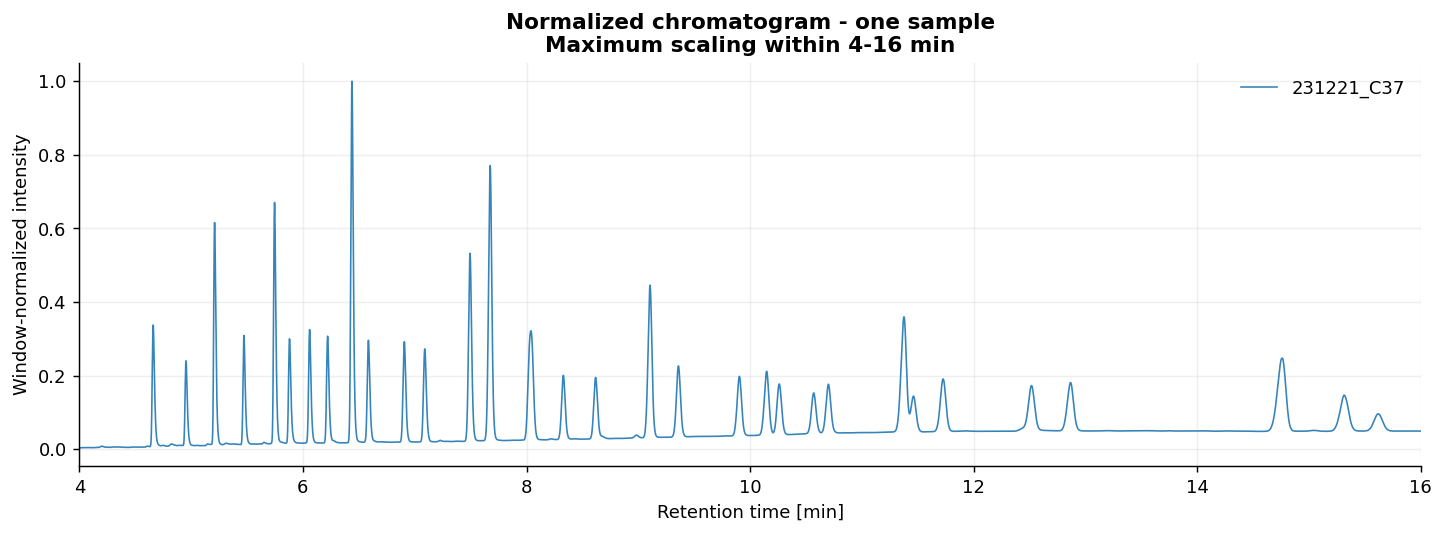

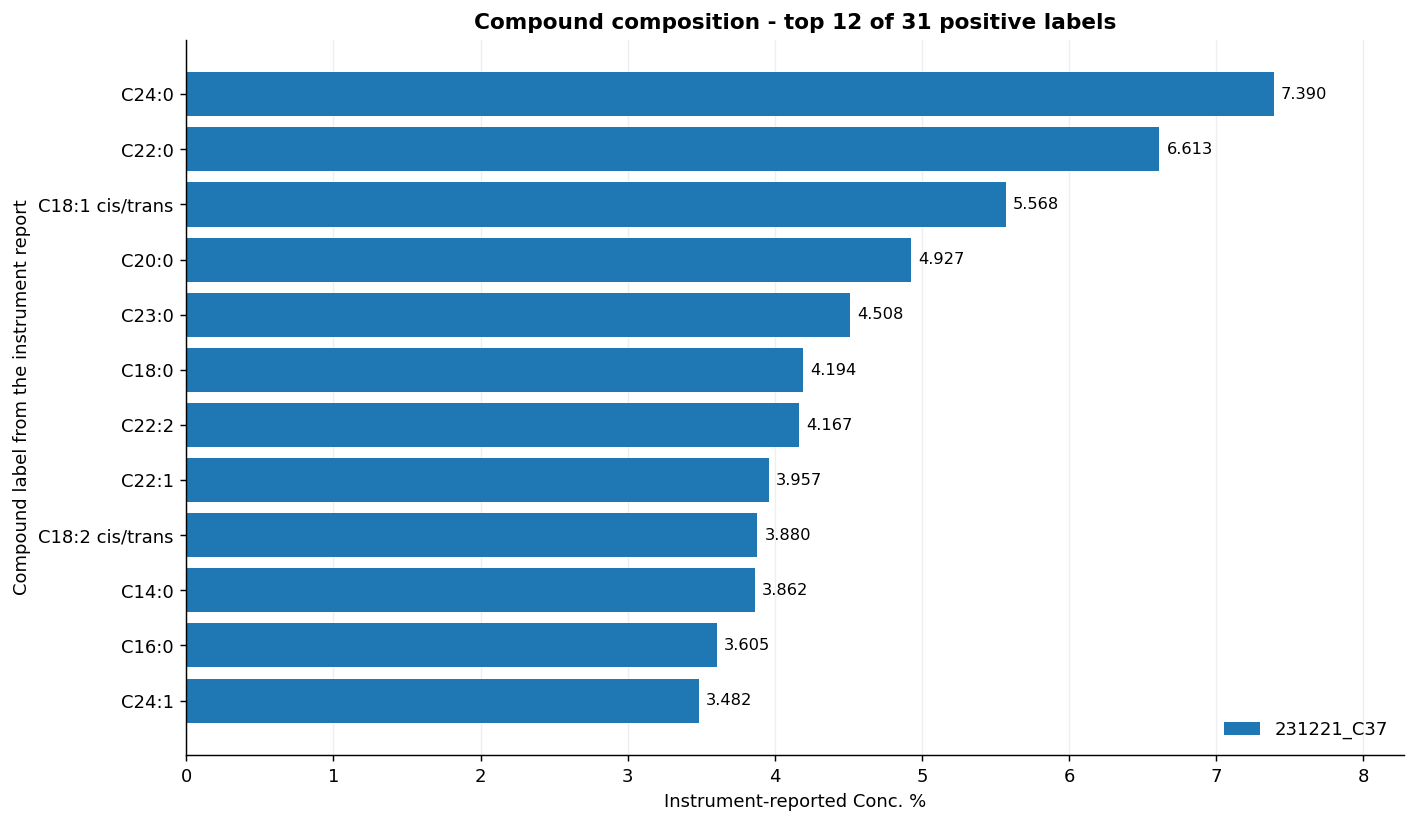

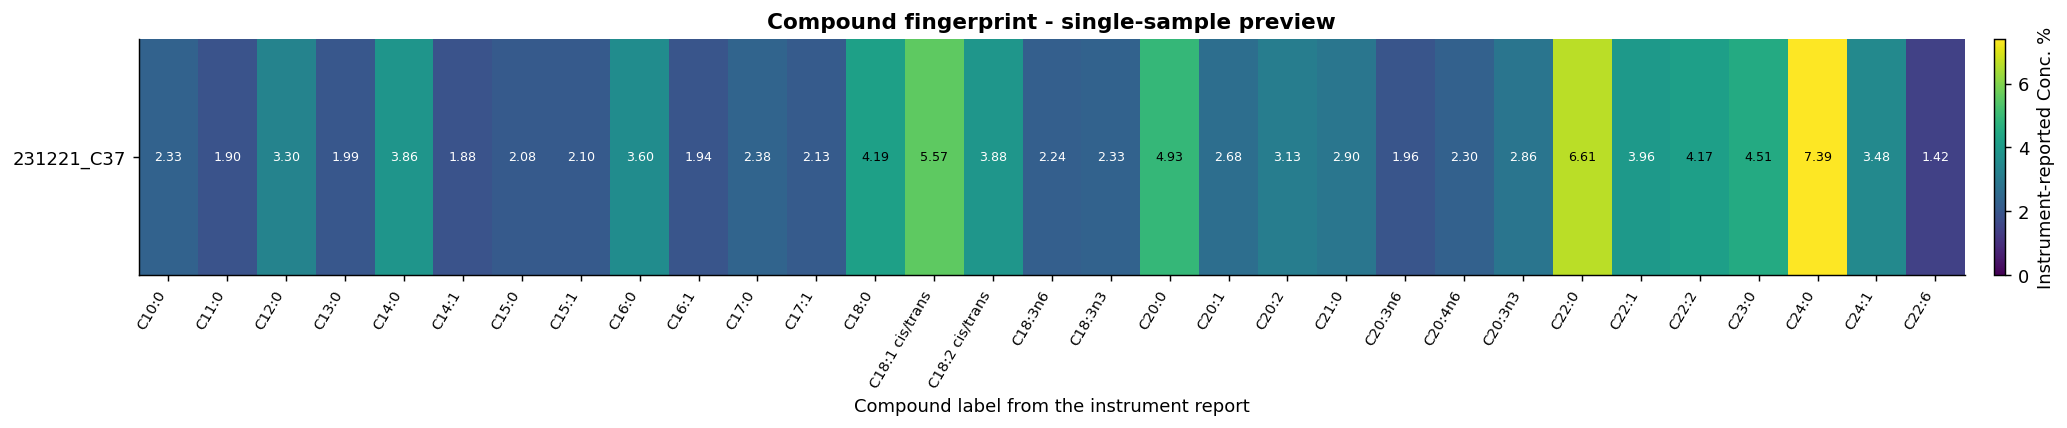

In [11]:
samples = load_samples(SAMPLE_FILES, ENCODING, SECTION, COMPOUND_SECTION)
print(f"Real sample files loaded: {len(samples)}")
for label, sample in samples.items():
    records = sample["compounds"]
    positive = sum(row["reported_percent"] > 0 for row in records)
    total = sum(row["reported_percent"] for row in records)
    print(f"{label}: {len(records)} compound rows, {positive} positive percentages, reported sum = {total:.3f}%")
if len(samples) == 1:
    print("Single-sample previews: add real reference files in SAMPLE_FILES for comparisons.")

overlay_figure = plot_normalized_overlay(samples, NORMALIZATION_START, NORMALIZATION_END, FIGURE_SIZE)
sample_names, compound_names, compound_matrix, value_label = build_compound_matrix(samples, COMPOUND_METRIC)
bar_figure = plot_compound_bars(sample_names, compound_names, compound_matrix, value_label, TOP_COMPOUNDS)
heatmap_figure = plot_compound_heatmap(sample_names, compound_names, compound_matrix, value_label, ANNOTATE_HEATMAP)

if SAVE_PLOTS:
    OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    overlay_figure.savefig(OUTPUT_DIRECTORY / OVERLAY_PLOT_FILENAME, dpi=DPI)
    bar_figure.savefig(OUTPUT_DIRECTORY / BAR_PLOT_FILENAME, dpi=DPI)
    heatmap_figure.savefig(OUTPUT_DIRECTORY / HEATMAP_PLOT_FILENAME, dpi=DPI)
plt.show()


## Scientific interpretation

- Matching retention times under the same analytical conditions can support a candidate identification. Coeluting compounds can share a retention time, so visual agreement alone does not establish identity.
- Peak area provides a quantitative signal, but response factors and calibration affect its conversion to concentration. Maximum-normalized intensity and uncorrected area percentages have different meanings.
- The file includes linear calibration coefficients. This notebook displays the exported `Conc. %` values; it does not independently validate those coefficients.
- Compound percentages and oil mixing fractions are different quantities. Estimating a two-oil mixture requires compatible reference profiles and a justified quantitative model.

Source: [Shimadzu — Analysis results of GC](https://www.shimadzu.eu/service-support/technical-support/analysis-basics/fundamentals/results.html).
